# NLP Assignment 2: Embeddings and Hidden Markov Models
Alexandria University — Computer and Systems Department

All algorithms are implemented from scratch with Python + NumPy. Hugging Face `datasets` is only used to download
CoNLL-2000; matplotlib is only used for plots. Supporting code lives in `src/` and the key implementations are
printed inline below so they are visible in the notebook.

## Setup and data

In [4]:
import sys, time, inspect, itertools
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
OUTPUTS = ROOT / "outputs"

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

from src.preprocessing import load_conll2000, train_val_split, words_of, tags_of
from src.hmm import model as hmm_model, viterbi as hmm_viterbi, evaluation as hmm_eval
from src.hmm.model import HMMTagger, signature_levels
from src.hmm.viterbi import viterbi
from src.hmm.evaluation import evaluate, format_results, per_tag_prf, top_confusions, confusion_matrix

SEED = 42
data = load_conll2000()
train_sents, val_sents = train_val_split(data["train"], val_fraction=0.1, seed=SEED)
test_sents = data["test"]
print(f"train: {len(train_sents)} sentences / {sum(map(len, train_sents))} tokens")
print(f"val:   {len(val_sents)} sentences / {sum(map(len, val_sents))} tokens")
print(f"test:  {len(test_sents)} sentences / {sum(map(len, test_sents))} tokens")
print("example:", train_sents[0][:8])

train: 8043 sentences / 190943 tokens
val:   894 sentences / 20784 tokens
test:  2013 sentences / 47377 tokens
example: [('Confidence', 'NN'), ('in', 'IN'), ('the', 'DT'), ('pound', 'NN'), ('is', 'VBZ'), ('widely', 'RB'), ('expected', 'VBN'), ('to', 'TO')]


The original training partition is split 90/10 into train/validation with a fixed seed (42), so the split is
reproducible. All tuning uses the validation set; the test partition is touched only once, for the final evaluation.
Chunk labels are dropped at load time.

# Part 1: Sparse and Dense Word Representations

*(to be added)*

In [17]:
from src.representations import (
    Vocabulary,
    PMIRepresentation,
    TFIDFRepresentation,
    Word2VecSGNS,
)

train_word_sents = [words_of(s) for s in train_sents]
val_word_sents = [words_of(s) for s in val_sents]

for mc in [1, 2, 3, 5]:
    v = Vocabulary(min_count=mc).fit(train_word_sents)
    print(
        f"min_count={mc}: vocab_size={len(v):>5} | "
        f"kept_tokens={v.kept_token_count:>6}/{v.raw_token_count} "
        f"({v.kept_token_count / v.raw_token_count:.1%})"
    )

vocab = Vocabulary(min_count=2).fit(train_word_sents)
print("\nTop 15 normalized tokens:", list(zip(vocab.idx2word[:15], vocab.counts[:15])))

min_count=1: vocab_size=14779 | kept_tokens=166606/190943 (87.3%)
min_count=2: vocab_size= 7871 | kept_tokens=159698/190943 (83.6%)
min_count=3: vocab_size= 5630 | kept_tokens=155216/190943 (81.3%)
min_count=5: vocab_size= 3683 | kept_tokens=148634/190943 (77.8%)

Top 15 normalized tokens: [('the', 9724), ('<NUM>', 5073), ('of', 4714), ('to', 4564), ('a', 4011), ('in', 3425), ('and', 3327), ('for', 1785), ("'s", 1726), ('that', 1720), ('is', 1264), ('it', 1084), ('said', 1076), ('on', 1047), ('at', 966)]


In [19]:
# Tune PMI hyperparameters on validation set via nearest-neighbor POS tag consistency
word_majority_tag = {}
tag_by_norm = {}
for s in train_sents:
    for w, t in s:
        nw = vocab.normalize(w)
        if nw is not None:
            tag_by_norm.setdefault(nw, Counter())[t] += 1
word_majority_tag = {w: cnt.most_common(1)[0][0] for w, cnt in tag_by_norm.items()}

val_eval_words = sorted({
    nw for s in val_word_sents for w in s
    if (nw := vocab.normalize(w)) is not None and nw in vocab.word2idx
})[:400]

def neighbor_pos_agreement(model, query_words, k=5):
    matches, total = 0, 0
    for w in query_words:
        g_tag = word_majority_tag.get(w)
        if not g_tag:
            continue
        nbrs = model.most_similar(w, top_k=k)
        for nw, _ in nbrs:
            if word_majority_tag.get(nw) == g_tag:
                matches += 1
            total += 1
    return matches / max(1, total)

print("Tuning PMI on validation words (top-5 neighbor POS agreement):")
best_pmi_cfg, best_pmi_score = None, -1.0
for mc in [2, 3]:
    for win in [2, 4, 6]:
        for pos in [True, False]:
            m = PMIRepresentation(window_size=win, positive=pos, min_count=mc).fit(train_word_sents)
            score = neighbor_pos_agreement(m, val_eval_words, k=5)
            print(f"  min_count={mc}, window={win}, positive={str(pos):<5} -> POS-agree={score:.4f}, nnz={m.nnz}")
            if score > best_pmi_score:
                best_pmi_score = score
                best_pmi_cfg = dict(window_size=win, positive=pos, min_count=mc)

pmi_model = PMIRepresentation(**best_pmi_cfg).fit(train_word_sents)
print("\nSelected PMI config:", best_pmi_cfg)

# Demonstrate how PMI differs from raw co-occurrence counts on "market"
q = "market"
qid = pmi_model._resolve_id(q)
raw_cooc = Counter()
for sent in train_word_sents:
    ids = pmi_model.vocab.encode_sentence(sent)
    for i, w in enumerate(ids):
        if w == qid:
            for j in range(max(0, i - best_pmi_cfg["window_size"]), min(len(ids), i + best_pmi_cfg["window_size"] + 1)):
                if i != j:
                    raw_cooc[pmi_model.vocab.idx2word[ids[j]]] += 1

top_pmi_ctx = sorted(pmi_model.vectors[qid].items(), key=lambda x: x[1], reverse=True)[:8]
print(f"\nTop contexts for '{q}' by RAW count:", raw_cooc.most_common(8))
print(f"Top contexts for '{q}' by PPMI:     ", [(pmi_model.vocab.idx2word[i], round(v, 2)) for i, v in top_pmi_ctx])

Tuning PMI on validation words (top-5 neighbor POS agreement):
  min_count=2, window=2, positive=True  -> POS-agree=0.2491, nnz=256445
  min_count=2, window=2, positive=False -> POS-agree=0.2496, nnz=278056
  min_count=2, window=4, positive=True  -> POS-agree=0.2025, nnz=448389
  min_count=2, window=4, positive=False -> POS-agree=0.2025, nnz=493771
  min_count=2, window=6, positive=True  -> POS-agree=0.1925, nnz=594690
  min_count=2, window=6, positive=False -> POS-agree=0.1900, nnz=660512
  min_count=3, window=2, positive=True  -> POS-agree=0.2639, nnz=231982
  min_count=3, window=2, positive=False -> POS-agree=0.2650, nnz=254330
  min_count=3, window=4, positive=True  -> POS-agree=0.2044, nnz=401095
  min_count=3, window=4, positive=False -> POS-agree=0.2049, nnz=447583
  min_count=3, window=6, positive=True  -> POS-agree=0.1967, nnz=528674
  min_count=3, window=6, positive=False -> POS-agree=0.1907, nnz=594873

Selected PMI config: {'window_size': 2, 'positive': False, 'min_count': 

In [22]:
print("Tuning TF-IDF on validation words:")
best_tfidf_cfg, best_tfidf_score = None, -1.0
for mc in [2, 3]:
    for sublinear in [False, True]:
        m = TFIDFRepresentation(sublinear_tf=sublinear, min_count=mc).fit(train_word_sents)
        score = neighbor_pos_agreement(m, val_eval_words, k=5)
        print(f"  min_count={mc}, sublinear_tf={str(sublinear):<5} -> POS-agree={score:.4f}, nnz={m.nnz}")
        if score > best_tfidf_score:
            best_tfidf_score = score
            best_tfidf_cfg = dict(sublinear_tf=sublinear, min_count=mc)

tfidf_model = TFIDFRepresentation(**best_tfidf_cfg).fit(train_word_sents)
print("\nSelected TF-IDF config:", best_tfidf_cfg)

Tuning TF-IDF on validation words:
  min_count=2, sublinear_tf=False -> POS-agree=0.1778, nnz=142711
  min_count=2, sublinear_tf=True  -> POS-agree=0.1788, nnz=142711
  min_count=3, sublinear_tf=False -> POS-agree=0.1654, nnz=138273
  min_count=3, sublinear_tf=True  -> POS-agree=0.1665, nnz=138273

Selected TF-IDF config: {'sublinear_tf': True, 'min_count': 2}


Max relative gradient error vs finite differences: 7.89e-07

Tuning Word2Vec SGNS on validation data:
  dim= 50, win=3, neg= 5, ep=12 -> val_loss=2.5260, POS-agree=0.2872 (51.1s)
  dim=100, win=3, neg= 5, ep=12 -> val_loss=2.5225, POS-agree=0.2782 (65.4s)
  dim=100, win=4, neg=10, ep=15 -> val_loss=3.1631, POS-agree=0.2727 (155.8s)
  dim=150, win=4, neg=10, ep=15 -> val_loss=3.1717, POS-agree=0.2702 (228.4s)

Selected Word2Vec config: {'embedding_dim': 100, 'window_size': 3, 'neg_samples': 5, 'lr': 0.025, 'epochs': 12, 'min_count': 2}
Epoch 01/12 | loss = 3.5002
Epoch 02/12 | loss = 2.7945
Epoch 03/12 | loss = 2.6423
Epoch 04/12 | loss = 2.5652
Epoch 05/12 | loss = 2.5150
Epoch 06/12 | loss = 2.4770
Epoch 07/12 | loss = 2.4416
Epoch 08/12 | loss = 2.4164
Epoch 09/12 | loss = 2.3931
Epoch 10/12 | loss = 2.3757
Epoch 11/12 | loss = 2.3627
Epoch 12/12 | loss = 2.3537


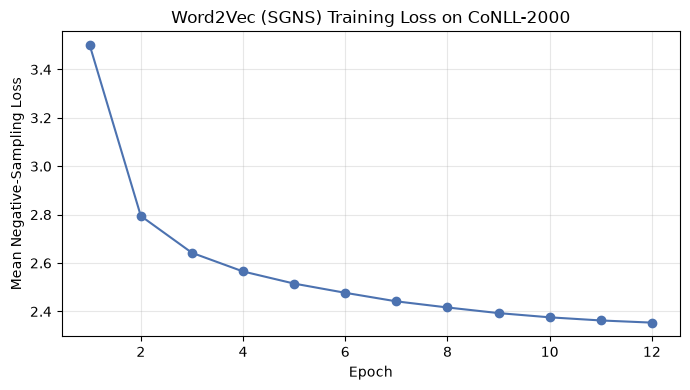

In [25]:
# 1. Numerical finite-difference gradient check
checker = Word2VecSGNS()
rel_err = checker.check_gradients()
print(f"Max relative gradient error vs finite differences: {rel_err:.2e}")
assert rel_err < 1e-5, "Analytical gradient mismatch!"

# 2. Tune Word2Vec hyperparameters on validation set
w2v_candidates = [
    dict(embedding_dim=50,  window_size=3, neg_samples=5,  lr=0.025, epochs=12, min_count=2),
    dict(embedding_dim=100, window_size=3, neg_samples=5,  lr=0.025, epochs=12, min_count=2),
    dict(embedding_dim=100, window_size=4, neg_samples=10, lr=0.025, epochs=15, min_count=2),
    dict(embedding_dim=150, window_size=4, neg_samples=10, lr=0.025, epochs=15, min_count=2),
]

print("\nTuning Word2Vec SGNS on validation data:")
best_w2v_cfg, best_val_loss = None, float("inf")
for cfg in w2v_candidates:
    t0 = time.time()
    m = Word2VecSGNS(**cfg, seed=SEED).fit(train_word_sents)
    vloss = m.validation_loss(val_word_sents)
    pos_ag = neighbor_pos_agreement(m, val_eval_words, k=5)
    print(
        f"  dim={cfg['embedding_dim']:>3}, win={cfg['window_size']}, neg={cfg['neg_samples']:>2}, "
        f"ep={cfg['epochs']:>2} -> val_loss={vloss:.4f}, POS-agree={pos_ag:.4f} ({time.time() - t0:.1f}s)"
    )
    if vloss < best_val_loss:
        best_val_loss = vloss
        best_w2v_cfg = cfg

print("\nSelected Word2Vec config:", best_w2v_cfg)
w2v_model = Word2VecSGNS(**best_w2v_cfg, seed=SEED).fit(train_word_sents, verbose=True)

# 3. Plot training loss curve
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(w2v_model.loss_history) + 1), w2v_model.loss_history, marker="o", color="#4C72B0")
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean Negative-Sampling Loss")
ax.set_title("Word2Vec (SGNS) Training Loss on CoNLL-2000")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUTS / "word2vec_training_loss.png", dpi=120)
plt.show()

In [26]:
query_words = ["market", "prices", "bank", "said", "rose", "financial", "monday"]

for qw in query_words:
    pmi_n = [f"{w} ({s:.2f})" for w, s in pmi_model.most_similar(qw, top_k=5)]
    tfidf_n = [f"{w} ({s:.2f})" for w, s in tfidf_model.most_similar(qw, top_k=5)]
    w2v_n = [f"{w} ({s:.2f})" for w, s in w2v_model.most_similar(qw, top_k=5)]
    print(f"Query: '{qw}' (majority POS: {word_majority_tag.get(qw, '?')})")
    print(f"  PMI:      {', '.join(pmi_n)}")
    print(f"  TF-IDF:   {', '.join(tfidf_n)}")
    print(f"  Word2Vec: {', '.join(w2v_n)}\n")

# Quantitative comparison of dimensionality, sparsity, POS-agreement, and storage cost
models = {
    "PMI (Sparse)": pmi_model,
    "TF-IDF (Sparse)": tfidf_model,
    "Word2Vec (Dense)": w2v_model,
}

print(f"{'Representation':<18} {'Shape':<16} {'Sparsity':>10} {'Storage (KB)':>14} {'Val POS-Agree@5':>16}")
print("-" * 78)
for name, m in models.items():
    shape_str = f"{m.shape[0]} x {m.shape[1]}"
    kb = m.storage_bytes() / 1024.0
    pos_ag = neighbor_pos_agreement(m, val_eval_words, k=5)
    print(f"{name:<18} {shape_str:<16} {m.sparsity:>9.2%} {kb:>13.1f} {pos_ag:>16.4f}")

Query: 'market' (majority POS: NN)
  PMI:      stock (0.13), friday (0.13), plunge (0.12), arena (0.12), price (0.11)
  TF-IDF:   the (0.22), stock (0.19), in (0.15), to (0.14), and (0.13)
  Word2Vec: participants (0.86), broad (0.85), commentary (0.81), gyrations (0.79), bull (0.78)

Query: 'prices' (majority POS: NNS)
  PMI:      oil (0.15), demand (0.13), sales (0.13), futures (0.12), stock (0.12)
  TF-IDF:   energy (0.18), wholesale (0.18), consumer (0.16), higher (0.15), oil (0.13)
  Word2Vec: crude (0.77), energy (0.77), selected (0.77), lower (0.76), pushed (0.75)

Query: 'bank' (majority POS: NN)
  PMI:      loan (0.15), financing (0.14), federal (0.13), banking (0.13), loans (0.12)
  TF-IDF:   loans (0.20), m$ (0.19), basir (0.18), credit (0.18), paid-up (0.17)
  Word2Vec: financing (0.86), contribution (0.81), control (0.78), proposed (0.78), loan (0.78)

Query: 'said' (majority POS: VBD)
  PMI:      mr. (0.20), chairman (0.19), spokesman (0.19), inc. (0.18), 's (0.18)
  TF-I

# Part 2: Hidden Markov Model and Viterbi

## 2.0 Preprocessing for tagging
For POS tagging the tokens are kept **as-is** (no lowercasing, no number normalisation): capitalisation separates
`NNP` from `NN`, and the surface form of numbers and punctuation is itself strong evidence. Unknown words are
handled inside the model (2.1), not by rewriting the text.

In [5]:
train_vocab = Counter(w for s in train_sents for w, _ in s)
tag_counts = Counter(t for s in train_sents for _, t in s)
def oov_rate(sents):
    toks = [w for s in sents for w, _ in s]
    return sum(w not in train_vocab for w in toks) / len(toks)
print(f"tagset size: {len(tag_counts)}   training vocabulary: {len(train_vocab)} word types")
print(f"hapax legomena (count == 1): {sum(c == 1 for c in train_vocab.values())}")
print(f"OOV rate  val: {oov_rate(val_sents):.2%}   test: {oov_rate(test_sents):.2%}")
print("most frequent tags:", tag_counts.most_common(10))

tagset size: 44   training vocabulary: 18202 word types
hapax legomena (count == 1): 9111
OOV rate  val: 4.58%   test: 7.25%
most frequent tags: [('NN', 27214), ('IN', 20550), ('NNP', 17942), ('DT', 16524), ('NNS', 12291), ('JJ', 11752), (',', 9702), ('.', 7950), ('CD', 7548), ('VBD', 6086)]


## 2.1 Estimating the HMM

A first-order HMM with tags as hidden states:

$$P(t_{1:T}, w_{1:T}) = \pi(t_1)\prod_{i=2}^{T}A(t_{i-1}, t_i)\; P(\langle/s\rangle \mid t_T)\prod_{i=1}^{T}B(t_i, w_i)$$

All three parameter sets are maximum-likelihood counts with smoothing:

* **Initial / transition / end** — add-$k$ (Lidstone):
  $A(i,j) = \dfrac{c(i,j) + k_A}{c(i,\cdot) + c(i,\langle/s\rangle) + k_A (N+1)}$. The end-of-sentence event is part of each
  row, so every row of $[A \mid \text{end}]$ sums to 1. Smoothing guarantees no tag bigram has zero probability.
* **Emissions** — words seen more than `rare_threshold` times are the known vocabulary. All rarer training tokens are
  collapsed into one `<UNK>` symbol per tag, so $P(\langle UNK\rangle \mid t)$ learns *how open each tag is to new
  words* (high for `NN`, `NNP`, `JJ`, `CD`; ~0 for `DT`, `IN`, `CC`). Add-$k_B$ smoothing over vocabulary + `<UNK>`.

**Unknown words.** For a word without its own emission:

$$P(w\mid t) = P(\langle UNK\rangle\mid t)\cdot P(\text{sig}(w)\mid\langle UNK\rangle, t)$$

`sig(w)` is an orthographic/morphological signature (all-caps, capitalised mid-sentence vs. sentence-initial, digits,
hyphen, numeric pattern, common suffix like *-ing, -ed, -tion, -ly, -s*). Signature distributions are estimated from
the rare training tokens at three levels (full → shape only → plain UNK, add-$k_s$ smoothed) and the most specific level
observed in training is used. Additionally, an unseen word whose **lowercase form is known** (typically a
capitalised sentence-initial word) reuses the lowercase word's emissions.

In [6]:
print(inspect.getsource(hmm_model))

"""First-order (bigram) HMM POS tagger estimated from tagged sentences.

Model
-----
    P(tags, words) = P(t_1) * prod_i P(t_i | t_{i-1}) * P(</s> | t_T) * prod_i P(w_i | t_i)

Smoothing
---------
* Initial / transition / end probabilities: add-k (Lidstone) smoothing, so every
  tag bigram has non-zero probability.
* Emissions: words seen more than ``rare_threshold`` times form the known
  vocabulary.  All rarer training tokens are collapsed into a single ``<UNK>``
  emission per tag, so P(<UNK> | t) learns how "open" each tag is (NN, JJ, NNP
  get a lot of mass; DT, IN, CC almost none).  Add-k smoothing is then applied
  over the known vocabulary + <UNK>.

Unknown words
-------------
For a word that is not in the known vocabulary:

    P(w | t) = P(<UNK> | t) * P(signature(w) | <UNK>, t)

where ``signature`` maps a word to a morphological/orthographic class
(capitalisation, digits, hyphens, common suffixes).  Signature distributions are
estimated from the rare training tokens at thre

In [7]:
for w, pos in [("reorganizing", 3), ("Mitsubishi", 4), ("Corp.", 5), ("1,234.5", 2), ("quickly", 1),
               ("anti-takeover", 6), ("IBM", 3), ("Yesterday", 0), ("transactions", 7)]:
    print(f"{w:<15} -> {signature_levels(w, pos)}")

reorganizing    -> ('UNK-ing', 'UNK', '<UNK>')
Mitsubishi      -> ('UNK-CAP', 'UNK-CAP', '<UNK>')
Corp.           -> ('UNK-CAP', 'UNK-CAP', '<UNK>')
1,234.5         -> ('UNK-NUM', 'UNK-NUM', '<UNK>')
quickly         -> ('UNK-ly', 'UNK', '<UNK>')
anti-takeover   -> ('UNK-DASH-er', 'UNK-DASH', '<UNK>')
IBM             -> ('UNK-ALLC', 'UNK-ALLC', '<UNK>')
Yesterday       -> ('UNK-INITC-y', 'UNK-INITC', '<UNK>')
transactions    -> ('UNK-s', 'UNK', '<UNK>')


## 2.2 Viterbi decoding

Dynamic programming over tags: $\delta_t(j) = \max_i[\delta_{t-1}(i) + \log A(i,j)] + \log B(j, w_t)$ with
back-pointers. Everything is in **log space**: a product of hundreds of probabilities underflows float64, while a sum
of log-probabilities does not, and `argmax` is unchanged because log is monotonic. The inner max over previous tags is
vectorised as an $N\times N$ NumPy operation, so decoding is $O(TN^2)$.

In [8]:
print(inspect.getsource(hmm_viterbi))

"""Log-space Viterbi decoding implemented with NumPy."""

from __future__ import annotations

import numpy as np


def viterbi(
    log_pi: np.ndarray,
    log_A: np.ndarray,
    log_emit: np.ndarray,
    log_end: np.ndarray | None = None,
) -> tuple[list[int], float]:
    """Most likely state sequence for one observation sequence.

    Args:
        log_pi:   (N,)   log P(t_1 = j)
        log_A:    (N, N) log P(t_i = j | t_{i-1} = i)
        log_emit: (T, N) log P(w_t | tag j) for every position of the sentence
        log_end:  (N,)   optional log P(</s> | t_T = j)

    Working entirely with log-probabilities turns products into sums, so long
    sentences never underflow the way raw probability products would.

    Returns:
        (best_path as list of state indices, its log-probability)
    """
    T, N = log_emit.shape
    if T == 0:
        return [], 0.0

    delta = log_pi + log_emit[0]                      # (N,)
    backptr = np.zeros((T, N), dtype=np.int32)

    for t in ra

**Sanity check** — on short random sentences, Viterbi must match exhaustive search over all $N^T$ tag sequences.

In [9]:
def brute_force(log_pi, log_A, log_emit, log_end):
    T, N = log_emit.shape
    best, best_path = -np.inf, None
    for path in itertools.product(range(N), repeat=T):
        s = log_pi[path[0]] + log_emit[0, path[0]] + log_end[path[-1]]
        s += sum(log_A[path[t-1], path[t]] + log_emit[t, path[t]] for t in range(1, T))
        if s > best:
            best, best_path = s, list(path)
    return best_path, best

rng = np.random.default_rng(0)
for trial in range(5):
    N, T = 5, rng.integers(1, 6)
    lp = np.log(rng.dirichlet(np.ones(N)))
    lA = np.log(rng.dirichlet(np.ones(N), size=N))
    lE = np.log(rng.random((T, N)))
    le = np.log(rng.random(N))
    p1, s1 = viterbi(lp, lA, lE, le)
    p2, s2 = brute_force(lp, lA, lE, le)
    assert p1 == p2 and np.isclose(s1, s2), (p1, p2)
print("Viterbi matches brute force on all trials.")

Viterbi matches brute force on all trials.


## 2.3 Hyperparameter tuning on the validation set

Grid over the rare-word threshold, transition $k_A$, emission $k_B$ and signature $k_s$ smoothing constants, with and
without lowercase back-off. Selection criterion: overall validation token accuracy (ties broken by unknown-word accuracy).

In [10]:
val_words = [words_of(s) for s in val_sents]
val_gold = [tags_of(s) for s in val_sents]

grid = dict(rare_threshold=[1, 2, 3], trans_k=[0.01, 0.1, 1.0], emit_k=[0.001, 0.01, 0.1],
            sig_k=[0.1, 1.0], lowercase_backoff=[True, False])
keys = list(grid)
rows = []
t0 = time.time()
for values in itertools.product(*grid.values()):
    params = dict(zip(keys, values))
    m = HMMTagger(**params).fit(train_sents)
    r = evaluate(val_gold, m.predict_many(val_words), val_words, m.is_oov)
    rows.append((r["all"]["accuracy"], r["unknown"]["accuracy"], params))
print(f"{len(rows)} configurations in {time.time() - t0:.1f}s")

rows.sort(key=lambda x: (x[0], x[1]), reverse=True)
print(f"{'val acc':>8} {'unk acc':>8}  params")
for acc, unk, p in rows[:10]:
    print(f"{acc:8.4f} {unk:8.4f}  {p}")
print("...worst:", f"{rows[-1][0]:.4f}", rows[-1][2])
best_params = rows[0][2]
print("\nselected:", best_params)

108 configurations in 63.1s
 val acc  unk acc  params
  0.9719   0.8456  {'rare_threshold': 1, 'trans_k': 0.01, 'emit_k': 0.001, 'sig_k': 0.1, 'lowercase_backoff': True}
  0.9719   0.8456  {'rare_threshold': 1, 'trans_k': 0.1, 'emit_k': 0.001, 'sig_k': 0.1, 'lowercase_backoff': True}
  0.9719   0.8403  {'rare_threshold': 1, 'trans_k': 0.01, 'emit_k': 0.001, 'sig_k': 0.1, 'lowercase_backoff': False}
  0.9718   0.8445  {'rare_threshold': 1, 'trans_k': 0.01, 'emit_k': 0.001, 'sig_k': 1.0, 'lowercase_backoff': True}
  0.9718   0.8445  {'rare_threshold': 1, 'trans_k': 0.1, 'emit_k': 0.001, 'sig_k': 1.0, 'lowercase_backoff': True}
  0.9718   0.8403  {'rare_threshold': 1, 'trans_k': 0.1, 'emit_k': 0.001, 'sig_k': 0.1, 'lowercase_backoff': False}
  0.9716   0.8477  {'rare_threshold': 1, 'trans_k': 1.0, 'emit_k': 0.001, 'sig_k': 0.1, 'lowercase_backoff': True}
  0.9716   0.8393  {'rare_threshold': 1, 'trans_k': 0.01, 'emit_k': 0.001, 'sig_k': 1.0, 'lowercase_backoff': False}
  0.9716   0.8435  

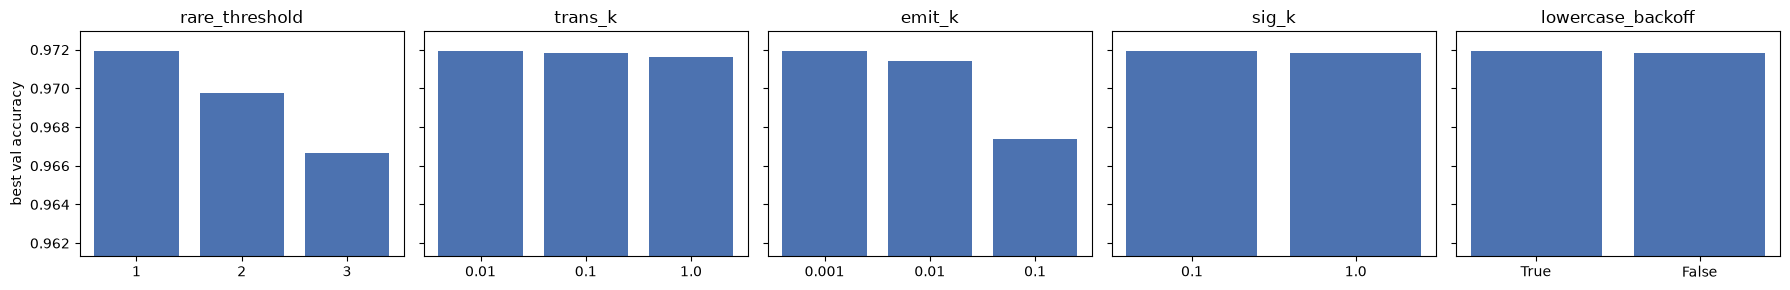

In [11]:
# Effect of each hyperparameter: best validation accuracy reachable with each value
fig, axes = plt.subplots(1, len(keys), figsize=(18, 3), sharey=True)
for ax, k in zip(axes, keys):
    vals = grid[k]
    best = [max(a for a, _, p in rows if p[k] == v) for v in vals]
    ax.bar([str(v) for v in vals], best, color="#4C72B0")
    ax.set_title(k); ax.set_ylim(min(a for a, _, _ in rows) - 0.002, max(best) + 0.001)
axes[0].set_ylabel("best val accuracy")
plt.tight_layout(); plt.savefig(OUTPUTS / "hmm_tuning.png", dpi=120); plt.show()

**Ablation of the unknown-word strategy** (validation set, other hyperparameters fixed at the selected values):

In [12]:
ablations = {
    "plain <UNK> only":           dict(best_params, use_signatures=False, lowercase_backoff=False),
    "+ signatures":               dict(best_params, use_signatures=True,  lowercase_backoff=False),
    "+ signatures + lowercase":   dict(best_params, use_signatures=True,  lowercase_backoff=True),
}
abl_results = {}
for name, p in ablations.items():
    m = HMMTagger(**p).fit(train_sents)
    abl_results[name] = evaluate(val_gold, m.predict_many(val_words), val_words, m.is_oov)
print(format_results(abl_results))

system                      subset      tokens      acc   macroP   macroR  macroF1       wP       wR      wF1
-------------------------------------------------------------------------------------------------------------
plain <UNK> only            all          20784   0.9461   0.9340   0.9461   0.9336   0.9473   0.9461   0.9462
plain <UNK> only            known        19832   0.9669   0.9514   0.9615   0.9517   0.9676   0.9669   0.9670
plain <UNK> only            unknown        952   0.5126   0.2708   0.2318   0.2405   0.4938   0.5126   0.4881
+ signatures                all          20784   0.9719   0.9531   0.9645   0.9543   0.9723   0.9719   0.9719
+ signatures                known        19832   0.9782   0.9575   0.9711   0.9599   0.9787   0.9782   0.9783
+ signatures                unknown        952   0.8403   0.5644   0.5386   0.5490   0.8335   0.8403   0.8340
+ signatures + lowercase    all          20784   0.9719   0.9480   0.9654   0.9517   0.9725   0.9719   0.9721
+ signatur

## 2.4 Final evaluation on the test set

The model is refit on the training split with the selected hyperparameters (the same training data the embeddings in
Part 1 use, so Part 3 compares like with like) and evaluated **once** on the untouched test partition.

*Unknown* = test token never seen in training; *known* = everything else. Because each token gets exactly one tag,
micro-averaged P/R/F1 equal accuracy, so macro (every tag equal) and support-weighted averages are reported too.

In [13]:
hmm = HMMTagger(**best_params).fit(train_sents)
test_words = [words_of(s) for s in test_sents]
test_gold = [tags_of(s) for s in test_sents]
t0 = time.time()
test_pred = hmm.predict_many(test_words)
print(f"decoded {len(test_sents)} sentences in {time.time() - t0:.2f}s")

baseline_results = evaluate(test_gold, test_pred, test_words, hmm.is_oov)
print(format_results({"baseline HMM": baseline_results}))

decoded 2013 sentences in 1.39s
system                      subset      tokens      acc   macroP   macroR  macroF1       wP       wR      wF1
-------------------------------------------------------------------------------------------------------------
baseline HMM                all          47377   0.9662   0.9255   0.9312   0.9224   0.9669   0.9662   0.9663
baseline HMM                known        43944   0.9768   0.9358   0.9565   0.9397   0.9772   0.9768   0.9769
baseline HMM                unknown       3433   0.8302   0.6807   0.6537   0.6532   0.8402   0.8302   0.8296


In [14]:
flat_gold = [t for s in test_gold for t in s]
flat_pred = [t for s in test_pred for t in s]
flat_words = [w for s in test_words for w in s]
flat_oov = [hmm.is_oov(w) for w in flat_words]

per_tag = per_tag_prf(flat_gold, flat_pred)
unk_tag = per_tag_prf([g for g, o in zip(flat_gold, flat_oov) if o], [p for p, o in zip(flat_pred, flat_oov) if o])
print(f"{'tag':<6}{'support':>8}{'P':>8}{'R':>8}{'F1':>8}   | unknown: {'support':>7}{'P':>8}{'R':>8}{'F1':>8}")
for t, m in sorted(per_tag.items(), key=lambda x: -x[1]["support"]):
    if m["support"] == 0: continue
    u = unk_tag.get(t)
    us = f"{u['support']:>7}{u['precision']:>8.3f}{u['recall']:>8.3f}{u['f1']:>8.3f}" if u and u["support"] else ""
    print(f"{t:<6}{m['support']:>8}{m['precision']:>8.3f}{m['recall']:>8.3f}{m['f1']:>8.3f}   |          {us}")

tag    support       P       R      F1   | unknown: support       P       R      F1
NN        6642   0.953   0.946   0.949   |              617   0.775   0.702   0.736
IN        5071   0.985   0.987   0.986   |                5   0.667   0.800   0.727
NNP       4806   0.977   0.952   0.964   |             1127   0.951   0.882   0.915
DT        4020   0.996   0.995   0.995   |                1   1.000   1.000   1.000
NNS       3034   0.961   0.980   0.970   |              386   0.827   0.904   0.864
JJ        2964   0.883   0.933   0.907   |              439   0.626   0.822   0.711
,         2390   1.000   1.000   1.000   |          
.         1975   0.999   1.000   1.000   |          
CD        1918   0.994   0.997   0.996   |              317   0.972   0.991   0.981
VBD       1679   0.956   0.930   0.943   |               51   0.750   0.647   0.695
RB        1354   0.945   0.932   0.939   |               63   0.891   0.905   0.898
VB        1269   0.924   0.930   0.927   |            

Most frequent confusions (gold -> predicted), all tokens:
     NN -> JJ    207
    NNP -> NN    105
    VBD -> VBN   104
     JJ -> NN    93
    VBN -> VBD   68
    NNP -> JJ    63
     RB -> IN    54
    VBZ -> NNS   51
    VBP -> VB    40
     NN -> VB    35

Most frequent confusions, unknown tokens:
     NN -> JJ    127
    NNP -> NN    57
     JJ -> NN    49
    NNP -> JJ    28
    VBN -> JJ    25
    NNP -> NNS   24
   NNPS -> NNS   18
   NNPS -> NNP   17
     NN -> VBG   16
    NNS -> JJ    15


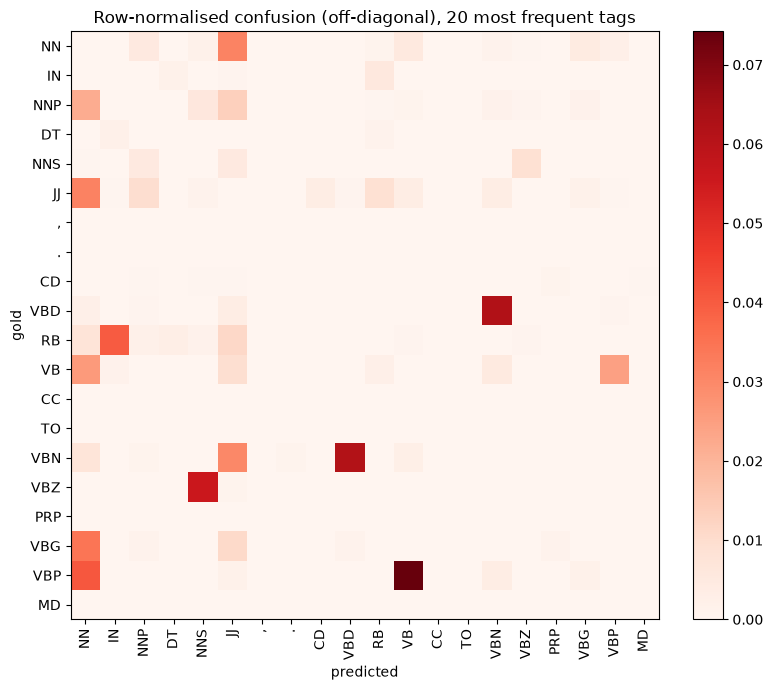

In [15]:
print("Most frequent confusions (gold -> predicted), all tokens:")
for g, p, n in top_confusions(flat_gold, flat_pred, 10):
    print(f"  {g:>5} -> {p:<5} {n}")
print("\nMost frequent confusions, unknown tokens:")
unk_pairs = [(g, p) for g, p, o in zip(flat_gold, flat_pred, flat_oov) if o]
for g, p, n in top_confusions(*zip(*unk_pairs), 10):
    print(f"  {g:>5} -> {p:<5} {n}")

tags_shown = [t for t, _ in Counter(flat_gold).most_common(20)]
mask = [g in tags_shown and p in tags_shown for g, p in zip(flat_gold, flat_pred)]
cm = confusion_matrix([g for g, m in zip(flat_gold, mask) if m], [p for p, m in zip(flat_pred, mask) if m], tags_shown)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
off = cm_norm.copy(); np.fill_diagonal(off, 0)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(off, cmap="Reds")
ax.set_xticks(range(len(tags_shown)), tags_shown, rotation=90); ax.set_yticks(range(len(tags_shown)), tags_shown)
ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title("Row-normalised confusion (off-diagonal), 20 most frequent tags")
fig.colorbar(im, fraction=0.046); plt.tight_layout(); plt.savefig(OUTPUTS / "hmm_confusion.png", dpi=120); plt.show()

In [16]:
# A few unknown-word errors in context
shown = 0
for ws, gs, ps in zip(test_words, test_gold, test_pred):
    for i, (w, g, p) in enumerate(zip(ws, gs, ps)):
        if hmm.is_oov(w) and g != p and shown < 12:
            ctx = " ".join(ws[max(0, i-3):i]) + f" [{w}] " + " ".join(ws[i+1:i+4])
            print(f"{g:>5} -> {p:<5} {signature_levels(w, i)[0]:<20} {ctx}")
            shown += 1

   NN -> JJ    UNK                  pressure floor , [torque] box , fixed
   JJ -> NN    UNK                  wings and an [aft] keel beam .
   NN -> JJ    UNK-DASH-ment        real-estate investment and [asset-management] duties , Mr.
   NN -> VBG   UNK-ing              in expected mortgage [servicing] fees , reflecting
   VB -> NN    UNK-INITC             [Look] at what happened
   NN -> JJ    UNK-DASH-tion        Tiger with combined [stock-option] gains of about
   NN -> JJ    UNK                  their spouses , [lifetime] access to the
  NNP -> JJ    UNK-CAP-ly           access to the [Friendly] Skies -- free
 NNPS -> NNS   UNK-CAP-es           to the Friendly [Skies] -- free first-class
  NNP -> NNS   UNK-CAP-es           US [Facilities] Corp. said Robert
 NNPS -> NNS   UNK-CAP-es           statement , US [Facilities] said Mr. Percival
 NNPS -> NNS   UNK-CAP-es           director , US [Facilities] said , but


## 2.5 Discussion

**Results.** The tuned HMM reaches **96.6% token accuracy** on the test set (weighted F1 0.966). On the
in-vocabulary tokens it reaches 97.7%, and on the 3,433 unknown tokens (7.3% of the test set) it reaches **83.0%**. The
test OOV rate is higher than the validation OOV rate (7.3% vs 4.6%), because validation sentences come from the same
sections as training. This is why test accuracy is a bit lower than validation accuracy (97.2%).

**Hyperparameters.**
* `rare_threshold = 1`: only hapaxes feed `<UNK>`. Higher thresholds strip real emission evidence from frequent-ish words, and
  the hapaxes alone already represent unseen words well (in the spirit of Good–Turing).
* `emit_k = 0.001`: this mattered most. A large emission $k$ gives closed-class tags (DT, IN) a noticeable probability for
  every word, which makes the tagger worse at telling tags apart.
* `trans_k`: barely matters (0.01 and 0.1 tie), because with ~190k tokens almost every useful tag bigram is observed.
* Lowercase back-off: leaves overall accuracy unchanged but raises unknown-word accuracy (84.0 → 84.6%) and unknown
  macro-F1 (0.55 → 0.71) on validation. It was chosen by the tie-break.

**Unknown-word handling is the main lever.** With a plain `<UNK>` emission, unknown-word accuracy is only 51%, because
every unseen word gets pushed toward the most "open" tag. Adding signatures raises it to 84% and also improves the
*known* words (96.7 → 97.8%), since a bad guess on an unknown word spreads through the transitions to its neighbours.

**Remaining errors** are the classic hard cases for an HMM:
* NN ↔ JJ for prenominal modifiers such as *torque box* and *lifetime access*. The left context (DT/JJ) fits both tags,
  and a bigram model cannot see the head noun that follows.
* VBD ↔ VBN (*-ed* forms). Telling them apart needs an auxiliary that may be several words back.
* NNPS → NNS / NNP for capitalised plurals like *US Facilities*. NNPS is rare, so its unknown recall is only 17%.
* NNP → NN/JJ for unseen capitalised words whose capitalisation signal is weak or misleading.

Signatures only look at the surface form of a word. They cannot tell that *torque* behaves like *engine* or
*pressure*, and that kind of distributional similarity is exactly what Part 3 adds with the embeddings.